### BNN specific analysis

- Prior predictive
- Tail analysis
- Posterior analysis with different samples sizes
- Performance across different warm up length
- Performance across different target scaling intervals
- Posterior weight distributions
- BNN model graph
- CDF comparison (QRNN and BNN)


In [ ]:
import sys
sys.path.append("../src")

from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpyro

import arviz as az
import properscoring as ps

from jax import random
from numpyro.infer import Predictive

from configs.load_config import load_config, dict_to_namespace
from data_processing.load import load_dataset
from data_processing.utils import load_checkpoint

from models.build import build_model
from models.model import model_mw_gamma_extended

from training.evaluate import evaluate_numpyro
from training.plot import (
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_family,
    cdf_comparison_plot
)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [44]:
%reload_ext autoreload

Prior predictive analysis


Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:706: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)


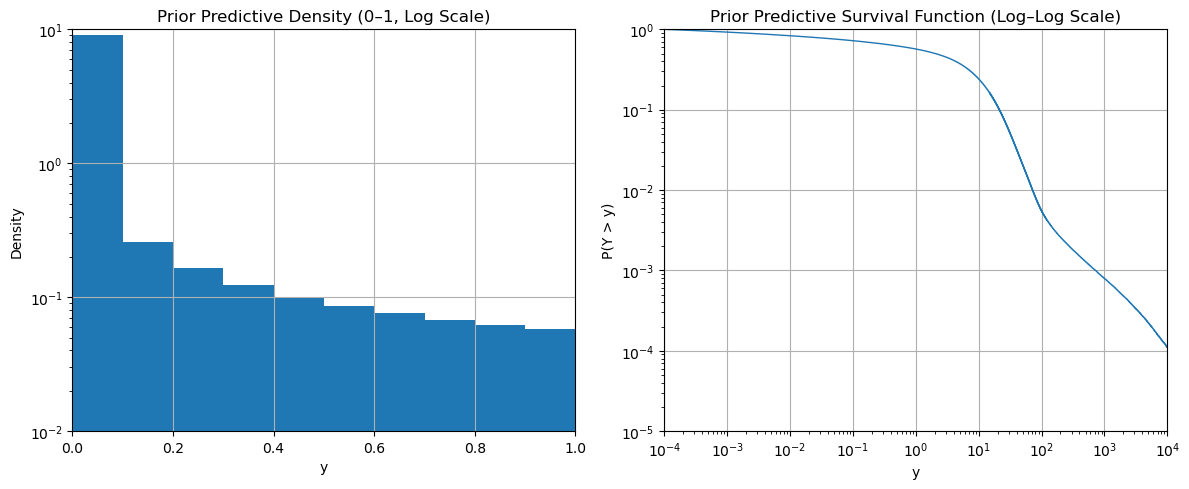

In [2]:
data_cfg = dict_to_namespace(
    {
        "dataset": "nowcast",
        "bid_zone": f"ELSPOT NO1",
        "split_time": "2025-01-01 00:00:00",
    }
)
data = load_dataset(data_cfg)

# prior predictive: no posterior_samples, no guide, just sample from priors
predictive = Predictive(
    model_mw_gamma_extended, num_samples=1000, return_sites=["Y", "mu", "alpha"]
)

samples = predictive(random.PRNGKey(0), X=data["X_train"], Y=None)


y = np.array(samples["Y"]).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Interval [0,1]
axes[0].hist(
    y,
    bins=10,
    range=(0, 1),
    density=True,
)

axes[0].set_xlabel("y")
axes[0].set_ylabel("Density")
axes[0].set_yscale("log")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(1e-2, 10)
axes[0].grid()
axes[0].set_title("Prior Predictive Density (0–1, Log Scale)")


# Tail / Survival
axes[1].hist(
    y,
    bins=np.logspace(-4, 8, 10000),
    cumulative=-1,
    density=True,
    histtype="step",
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(1e-4, 1e4)
axes[1].set_ylim(1e-5, 1)
axes[1].set_xlabel("y")
axes[1].set_ylabel("P(Y > y)")
axes[1].grid()
axes[1].set_title("Prior Predictive Survival Function (Log–Log Scale)")


plt.tight_layout()
plt.savefig("../plots/prior_predictive.pdf")

In [3]:
model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted_100.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3"

In [4]:
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [5]:
data = load_dataset(data_cfg)
checkpoint = load_checkpoint(file_name=file_name)

Loading forecast data for ELSPOT NO3, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-04-07 15:25:44
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Final columns: 79
All parks operational from 2022-10-12 12:00:00
Before 2-day ahead filtering: 1316376 rows
After 2-day ahead filtering: 489192 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (18069, 24, 15, 10)
Preprocessing done. X_test shape: (1895, 24, 15, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3.pkl


Posterior analysis


In [ ]:
def evaluate_sample_sizes(predictions, y_test, sample_sizes):

    results = []

    for n in sample_sizes:
        subset = predictions[:n]  # first n retained samples

        # Posterior predictive mean for point prediction
        pred_mean = subset.mean(axis=0)
        pred_median = np.percentile(subset, 50, axis=0)

        rmse_n = np.sqrt(np.mean((pred_median - y_test) ** 2))
        crps_n = ps.crps_ensemble(y_test, subset, axis=0).mean()

        hdis = az.hdi(np.expand_dims(subset, axis=0), hdi_prob=0.95)
        hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]
        width = (hdi_upper - hdi_lower).mean()

        results.append(
            {"n_samples": n, "RMSE": rmse_n, "CRPS": crps_n, "HDI width": width}
        )

    return pd.DataFrame(results)


def evaluate_sample_subsets(
    data,
    file_name,
    checkpoint,
    sample_sizes=[
        25,
        50,
        75,
        100,
        150,
        200,
        250,
        300,
        350,
        400,
        450,
        500,
        550,
        600,
        650,
        700,
        750,
        800,
    ],
):
    results_dfs = []

    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], data)
    samples = checkpoint["samples"]
    predictive = Predictive(
        model,
        samples,
        return_sites=["mu", "alpha", "Y"],
    )

    for member in range(15):

        if model_cfg.backend == "numpyro":

            pp_samples = predictive(
                checkpoint["rng_key_predict"], X=data["X_test"][:, :, member], Y=None
            )
            y_pred = pp_samples["Y"]
            results_df = evaluate_sample_sizes(y_pred, data["Y_test_gen"], sample_sizes)
            results_dfs.append(results_df)

        if data_cfg.dataset == "nowcast":
            # validate on nowcast, only one loop, otherwise validation on all ensemble members
            print("break")
            break

    result = pd.concat(results_dfs).groupby("n_samples", as_index=False).mean()

    return result


results = evaluate_sample_subsets(data, file_name, checkpoint)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3.pkl


In [7]:
results

,n_samples,RMSE,CRPS,HDI width
0,25,296.323761,167.697418,577.764321
1,50,295.135529,165.794549,628.852710
2,75,294.624420,164.729561,645.875727
3,100,293.718140,164.340660,659.362825
4,150,293.128418,164.014429,652.612815
5,200,293.237427,164.033442,664.955022
6,250,293.286133,164.009427,662.176984
7,300,293.273285,163.965157,670.286722
8,350,293.328217,163.978647,666.762686
9,400,293.099060,163.925589,670.200750


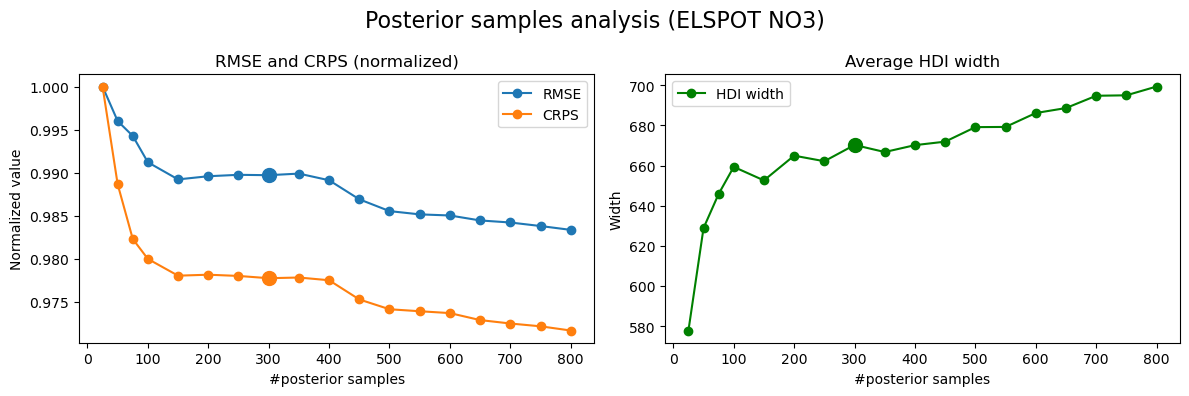

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Final value
idx = list(results["n_samples"]).index(300)

# Plot 1: RMSE + CRPS
axes[0].plot(
    results["n_samples"],
    results["RMSE"] / results["RMSE"].max(),
    marker="o",
    label="RMSE",
)
axes[0].plot(
    results["n_samples"],
    results["CRPS"] / results["CRPS"].max(),
    marker="o",
    label="CRPS",
)

# Highlight final setup
axes[0].scatter(
    results["n_samples"][idx],
    (results["RMSE"] / results["RMSE"].max())[idx],
    s=100,
    zorder=3,
)
axes[0].scatter(
    results["n_samples"][idx],
    (results["CRPS"] / results["CRPS"].max())[idx],
    s=100,
    zorder=3,
)

axes[0].set_title("RMSE and CRPS (normalized)")
axes[0].set_xlabel("#posterior samples")
axes[0].set_ylabel("Normalized value")
axes[0].legend()

# Plot 2: HDI width
axes[1].plot(
    results["n_samples"],
    results["HDI width"],
    marker="o",
    label="HDI width",
    color="green",
)
# Highlight final setup
axes[1].scatter(
    results["n_samples"][idx], results["HDI width"][idx], s=100, zorder=3, color="green"
)
axes[1].set_title("Average HDI width")
axes[1].set_xlabel("#posterior samples")
axes[1].set_ylabel("Width")
axes[1].legend()

fig.suptitle(f"Posterior samples analysis ({model_cfg.data.bid_zone})", fontsize=16)

plt.tight_layout()
plt.savefig("../plots/posterior_samples.pdf")

Warm up sample analysis


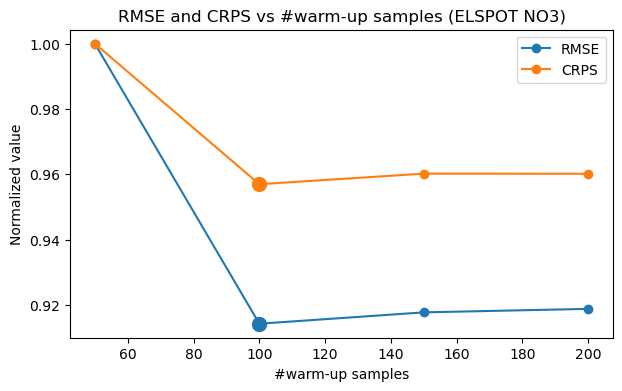

In [9]:
results = [
    {"warm-up samples": 50, "rmse": 215.385, "crps": 106.483},
    {"warm-up samples": 100, "rmse": 196.922, "crps": 101.903},
    {"warm-up samples": 150, "rmse": 197.671, "crps": 102.248},
    {"warm-up samples": 200, "rmse": 197.902, "crps": 102.244},
]

# Extract values
samples = [r["warm-up samples"] for r in results]
rmse = [r["rmse"] for r in results]
crps = [r["crps"] for r in results]


idx = list(samples).index(100)

# Plot
plt.figure(figsize=(7, 4))
plt.plot(samples, rmse / np.max(rmse), marker="o", label="RMSE")
plt.plot(samples, crps / np.max(crps), marker="o", label="CRPS")

# Highlight final value
plt.scatter(samples[idx], rmse[idx] / np.max(rmse), s=100, zorder=3)
plt.scatter(samples[idx], crps[idx] / np.max(crps), s=100, zorder=3)

plt.xlabel("#warm-up samples")
plt.ylabel("Normalized value")
plt.title("RMSE and CRPS vs #warm-up samples (ELSPOT NO3)")
plt.legend()

plt.savefig("../plots/warm-up-samples.pdf")

Target scaling experiment


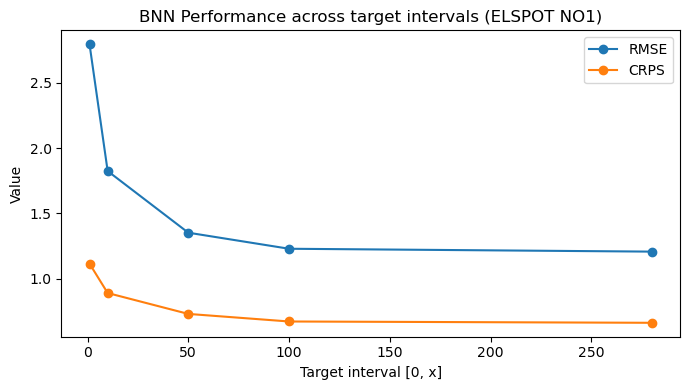

In [10]:
results = [
    {"interval": 1, "rmse": 2.795, "crps": 1.115},
    {"interval": 10, "rmse": 1.824, "crps": 0.890},
    {"interval": 50, "rmse": 1.352, "crps": 0.730},
    {"interval": 100, "rmse": 1.229, "crps": 0.672},
    {"interval": 280, "rmse": 1.207, "crps": 0.662},
]

# Extract values
intervals = [r["interval"] for r in results]
rmse = [r["rmse"] for r in results]
crps = [r["crps"] for r in results]

# Plot
plt.figure(figsize=(7, 4))
plt.plot(intervals, rmse, marker="o", label="RMSE")
plt.plot(intervals, crps, marker="o", label="CRPS")

plt.xlabel("Target interval [0, x]")
plt.ylabel("Value")
plt.title("BNN Performance across target intervals (ELSPOT NO1)")
plt.legend()
plt.tight_layout()
plt.savefig("../plots/target_scaling.pdf")

Posterior distributions


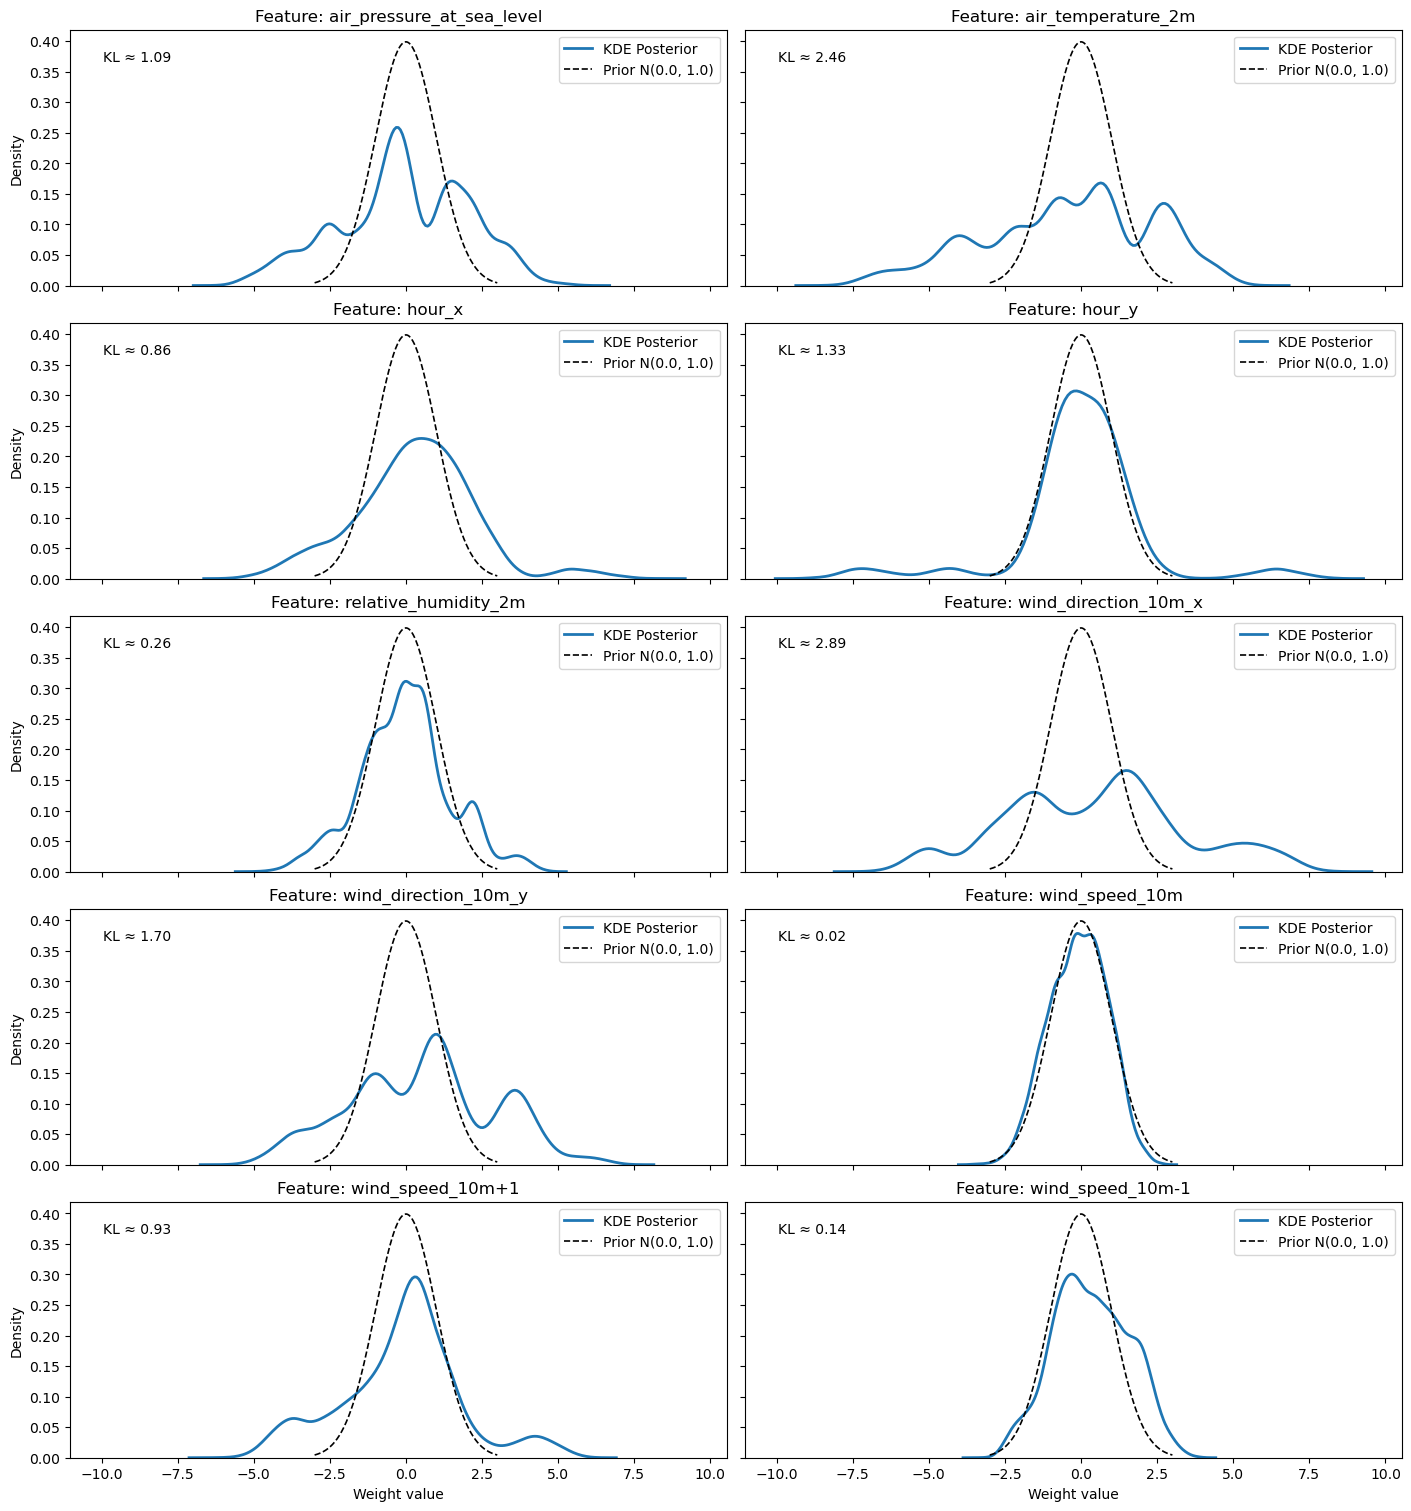

In [12]:
plot_first_layer_feature_posteriors(checkpoint["samples"], data)

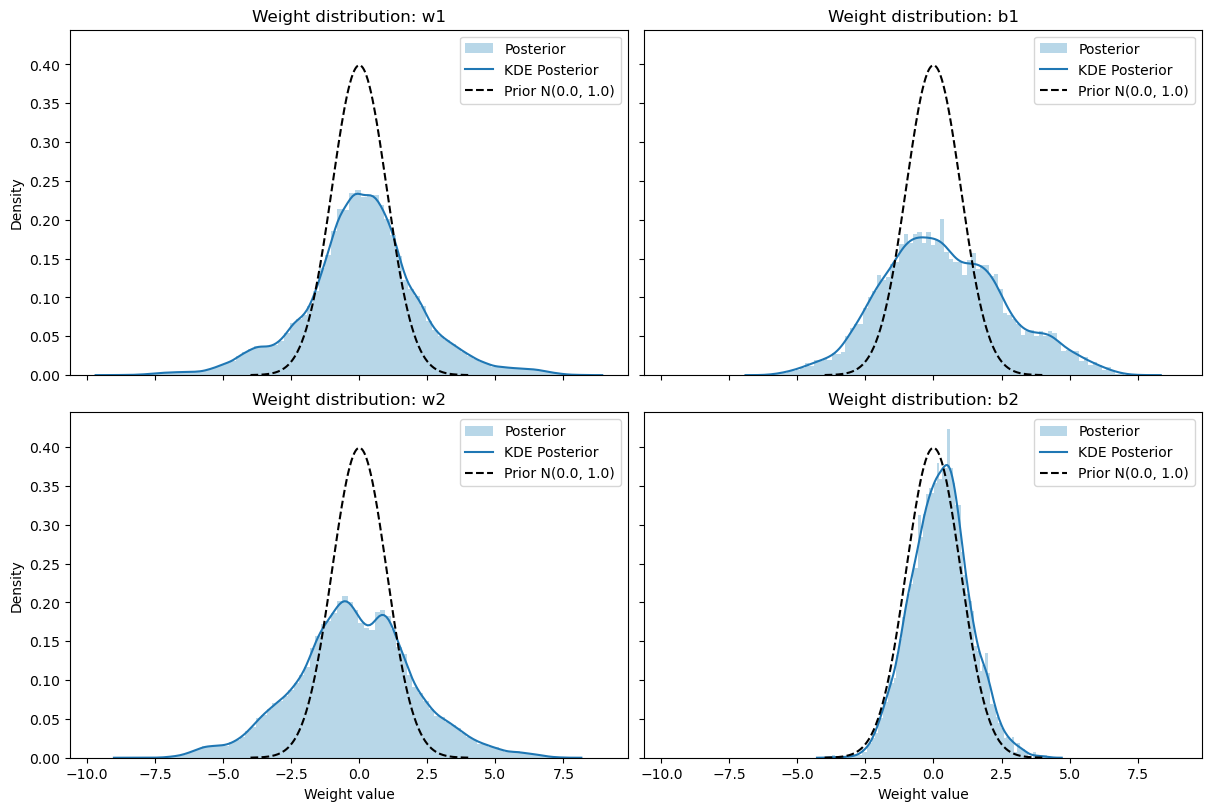

In [13]:
plot_bnn_weight_posteriors(checkpoint["samples"])

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3.pkl
model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3

Training statistics:
   RMSE train: 251.38686
   CRPS train:  131.86586346895248

Training statistics:
   RMSE train: 297.37152
   CRPS train:  162.52097377078735

Training statistics:
   RMSE train: 290.18695
   CRPS train:  157.2310098330075

Training statistics:
   RMSE train: 294.43304
   CRPS train:  160.2272008193605

Training statistics:
   RMSE train: 296.29504
   CRPS train:  162.22474061321896

Training statistics:
   RMSE train: 292.57364
   CRPS train:  159.41039093800532

Training statistics:
   RMSE train: 297.43405
   CRPS train:  160.9274830146682

Training statistics:
   RMSE train: 293.0947
   CRPS train:  159.50656912171445

Training statistics:
   RMSE train: 293.8537
   CRPS train:  160.3574273481642

Training statistics:
   RMSE train: 299.85147
   CRPS train:  162.5007461643739

Training st

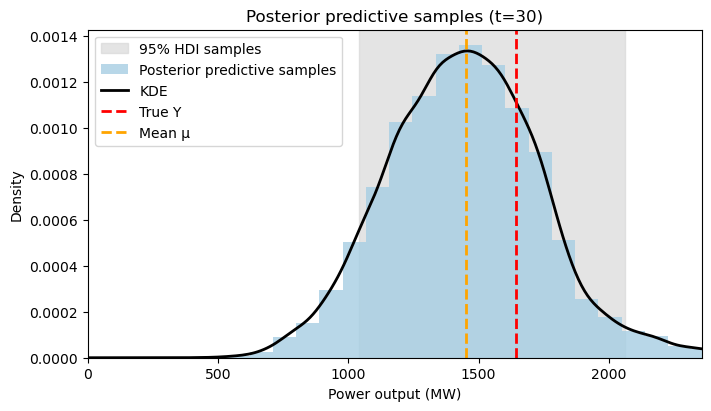

In [42]:
# TODO: plot macht keinen sinn, verwendet nur letzte predictive
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []
predictives = []

checkpoint = load_checkpoint(file_name=file_name)
print(file_name)
for member in range(15):

    model = build_model(checkpoint["model_cfg"], data)
    samples = checkpoint["samples"]
    metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
        model=model,
        samples=checkpoint["samples"],
        rng_key_predict=checkpoint["rng_key_predict"],
        data=data,
        model_cfg=checkpoint["model_cfg"],
        member=member,
    )

    hdi_list.append(hdis)
    predictives.append(predictive)

plot_posterior_predictive_family(predictives, model_cfg, data, t=30, hdi=hdis.T)

Model visualization


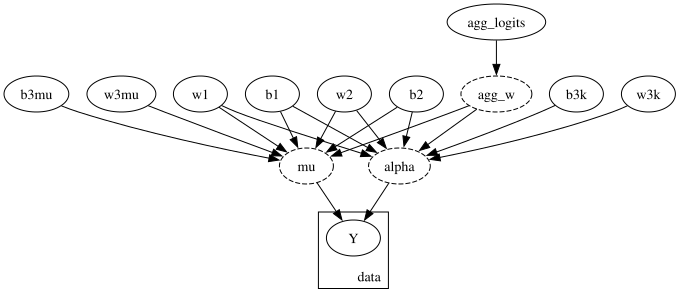

In [45]:
X_test = data["X_test"]
model = build_model(checkpoint["model_cfg"], data)
if len(X_test.shape) == 4:
    X_test = X_test[:, :, 0]

numpyro.render_model(
    model,
    model_args=(X_test,),
)

Compare CDFs of BNN and QRNN at one timestamp


Loading forecast data for ELSPOT NO4, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO4 and nowcast
  Saved at: 2026-04-07 15:27:48
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Final columns: 79
All parks operational from 2022-11-29 15:00:00
Before 2-day ahead filtering: 675532 rows
After 2-day ahead filtering: 251199 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (16878, 13, 15, 10)
Preprocessing done. X_test shape: (1895, 13, 15, 10)
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted

Training statistics:
   RMSE train: 125.006
   CRPS train: 67.173
   Coverage 2.5-97.5 train: 0.818
   Coverage 0-50 train: 0.285
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4.pkl

Training statistics:
   RMSE train: 112.48733
   CRPS train:  61.41643060154693
Loaded model: WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4.pt
  Model class: WindPowerQuantile_weighted

Training statistics:
   RMSE train: 136.441
   CRPS train: 75.36
   Coverage 2.5-97.5 train: 0.78
   Coverage 0-50 train: 0.294
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4.pkl

Training statistics:
  

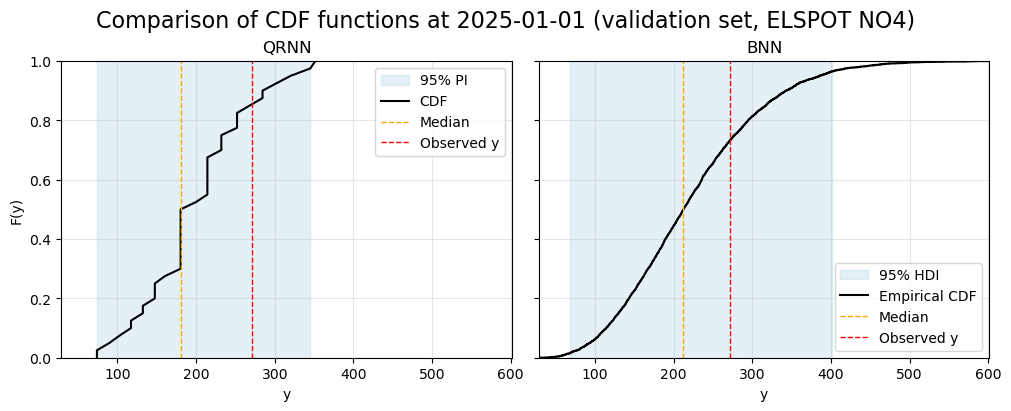

In [46]:
model_cfg_BNN = load_config("../configs/model/bnn_gen_model_nowcast_04_weighted.yaml")
data_cfg = load_config(model_cfg_BNN.data.path)
file_name_BNN = "model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4"

model_cfg_QRNN = load_config("../configs/model/torch_model_quantile_04.yaml")
file_name_QRNN = "WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4"

cdf_comparison_plot(
    11, model_cfg_BNN, model_cfg_QRNN, data_cfg, file_name_BNN, file_name_QRNN
)